In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchmetrics
import torchvision
import torchvision.transforms.v2 as T
from scipy.spatial.transform import Rotation
from torch.utils.data import DataLoader, TensorDataset, Dataset
import torch.nn.functional as F
from sklearn.manifold import TSNE
import matplotlib as mpl
from collections import namedtuple

In [4]:
if torch.cuda.is_available():
    device = "cuda"
else:
    device = "mps"

In [3]:
device

'mps'

In [4]:
plt.rc("font", size=14)
plt.rc("axes", labelsize=14, titlesize=14)
plt.rc("legend", fontsize=14)
plt.rc("xtick", labelsize=10)
plt.rc("ytick", labelsize=10)

In [5]:
def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            if isinstance(y_pred, tuple):
                y_pred = y_pred.output
            metric.update(y_pred, y_batch)
    return metric.compute()


def train(
    model,
    optimizer,
    loss_fn,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    patience=2,
    factor=0.5,
    epoch_callback=None,
):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=patience, factor=factor
    )
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        if epoch_callback is not None:
            epoch_callback(model, epoch)
        for index, (X_batch, y_batch) in enumerate(train_loader):
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad()
            if isinstance(y_pred, tuple):
                y_pred = y_pred.output
            metric.update(y_pred, y_batch)
            train_metric = metric.compute().item()
            print(f"\rBatch {index + 1}/{len(train_loader)}", end="")
            print(f", loss={total_loss / (index + 1):.4f}", end="")
            print(f", {train_metric=:.3f}", end="")
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(train_metric)
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        scheduler.step(val_metric)
        print(
            f"\rEpoch {epoch + 1}/{n_epochs},                      "
            f"train loss: {history['train_losses'][-1]:.4f}, "
            f"train metric: {history['train_metrics'][-1]:.3}, "
            f"valid metric: {history['valid_metrics'][-1]:.3}"
        )
    return history


In [34]:
torch.manual_seed(42)
encoder = nn.Linear(3, 2)
decoder = nn.Linear(2, 3)
autoencoder = nn.Sequential(encoder, decoder).to(device)

In [35]:
def generate_data(m, seed=42):
    X = np.zeros((m, 3))  # initialize 3D dataset
    rng = np.random.default_rng(seed)
    angles = (rng.random(m) ** 3 + 0.5) * 2 * np.pi  # uneven distribution
    X[:, 0], X[:, 1] = np.cos(angles), np.sin(angles) * 0.5  # oval
    X += 0.28 * rng.standard_normal((m, 3))  # add more noise
    X = Rotation.from_rotvec([np.pi / 29, -np.pi / 20, np.pi / 4]).apply(X)
    X += [0.2, 0, 0.2]  # shift a bit
    return torch.from_numpy(X.astype(np.float32))

In [36]:
X_train = generate_data(60, seed=42)
train_set = TensorDataset(X_train, X_train)
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)

In [37]:
X_valid = generate_data(500, seed=43)
valid_set = TensorDataset(X_valid, X_valid)
valid_loader = DataLoader(valid_set, batch_size=32)

In [10]:
torch.manual_seed(42)

optimizer = torch.optim.NAdam(autoencoder.parameters(), lr=0.2)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train(
    autoencoder, optimizer, mse, rmse, train_loader, valid_loader, n_epochs=20
)

Epoch 1/20,                      train loss: 0.1621, train metric: 0.406, valid metric: 0.309
Epoch 2/20,                      train loss: 0.0697, train metric: 0.264, valid metric: 0.297
Epoch 3/20,                      train loss: 0.0644, train metric: 0.253, valid metric: 0.324
Epoch 4/20,                      train loss: 0.0935, train metric: 0.303, valid metric: 0.45
Epoch 5/20,                      train loss: 0.1088, train metric: 0.336, valid metric: 0.245
Epoch 6/20,                      train loss: 0.0415, train metric: 0.203, valid metric: 0.235
Epoch 7/20,                      train loss: 0.0426, train metric: 0.205, valid metric: 0.273
Epoch 8/20,                      train loss: 0.0470, train metric: 0.218, valid metric: 0.211
Epoch 9/20,                      train loss: 0.0314, train metric: 0.179, valid metric: 0.213
Epoch 10/20,                      train loss: 0.0300, train metric: 0.174, valid metric: 0.209
Epoch 11/20,                      train loss: 0.0300, train 

In [11]:
codings = encoder(X_train.to(device))

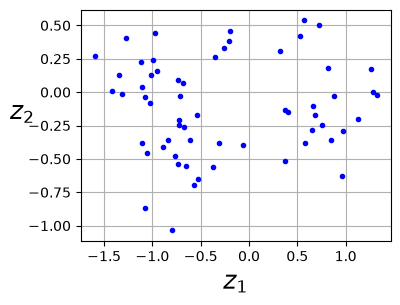

In [12]:
fig = plt.figure(figsize=(4, 3))
codings_np = codings.cpu().detach().numpy()
plt.plot(codings_np[:, 0], codings_np[:, 1], "b.")
plt.xlabel("$z_1$", fontsize=18)
plt.ylabel("$z_2$", fontsize=18, rotation=0)
plt.grid(True)

plt.show()

> Implemeting a Stacked Autoencoder Using PyTorch


In [12]:
stacked_encoder = nn.Sequential(
    nn.Flatten(), nn.Linear(1 * 28 * 28, 128), nn.ReLU(), nn.Linear(128, 32), nn.ReLU()
)
stacked_decoder = nn.Sequential(
    nn.Linear(32, 128),
    nn.ReLU(),
    nn.Linear(128, 1 * 28 * 28),
    nn.Sigmoid(),
    nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)),
)

stacked_ae = nn.Sequential(stacked_encoder, stacked_decoder).to(device)


In [6]:
toTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])

train_and_valid_data = torchvision.datasets.FashionMNIST(
    root="datasets", train=True, download=True, transform=toTensor
)
test_data = torchvision.datasets.FashionMNIST(
    root="datasets", train=False, download=True, transform=toTensor
)

torch.manual_seed(42)
train_data, valid_data = torch.utils.data.random_split(
    train_and_valid_data, [55_000, 5_000]
)


In [7]:
class AutoencoderDataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        x, _ = self.base_dataset[idx]
        return x, x


train_loader = DataLoader(AutoencoderDataset(train_data), batch_size=32, shuffle=True)
valid_loader = DataLoader(AutoencoderDataset(valid_data), batch_size=32)
test_loader = DataLoader(AutoencoderDataset(test_data), batch_size=32)

In [45]:
optimizer = torch.optim.NAdam(stacked_ae.parameters(), lr=0.01)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train(
    stacked_ae, optimizer, mse, rmse, train_loader, valid_loader, n_epochs=10
)

Epoch 1/10,                      train loss: 0.0249, train metric: 0.158, valid metric: 0.144
Epoch 2/10,                      train loss: 0.0196, train metric: 0.14, valid metric: 0.138
Epoch 3/10,                      train loss: 0.0187, train metric: 0.137, valid metric: 0.136
Epoch 4/10,                      train loss: 0.0182, train metric: 0.135, valid metric: 0.135
Epoch 5/10,                      train loss: 0.0161, train metric: 0.127, valid metric: 0.128
Epoch 6/10,                      train loss: 0.0158, train metric: 0.126, valid metric: 0.127
Epoch 7/10,                      train loss: 0.0156, train metric: 0.125, valid metric: 0.125
Epoch 8/10,                      train loss: 0.0147, train metric: 0.121, valid metric: 0.122
Epoch 9/10,                      train loss: 0.0145, train metric: 0.12, valid metric: 0.122
Epoch 10/10,                      train loss: 0.0144, train metric: 0.12, valid metric: 0.121


In [21]:
def plot_image(image):
    plt.imshow(image.permute(1, 2, 0).cpu(), cmap="binary")
    plt.axis("off")


def plot_reconstructions(model, images, n_images=5):
    images = images[:n_images]
    with torch.no_grad():
        y_pred = model(images.to(device))
    if isinstance(y_pred, tuple):
        y_pred = y_pred.output
    fig = plt.figure(figsize=(len(images) * 1.5, 3))
    for idx in range(len(images)):
        plt.subplot(2, len(images), 1 + idx)
        plot_image(images[idx])
        plt.subplot(2, len(images), 1 + len(images) + idx)
        plot_image(y_pred[idx])

In [10]:
X_valid = torch.stack([x for x, _ in valid_data])
# plot_reconstructions(stacked_ae, X_valid)
# plt.show()

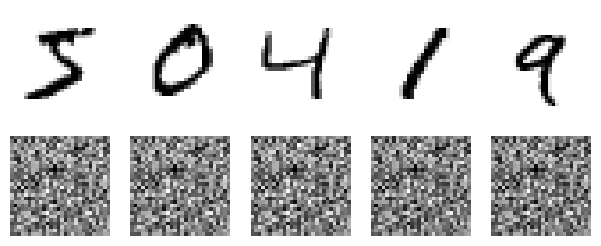

In [13]:
torch.manual_seed(42)
mnist_data = torchvision.datasets.MNIST(
    root="datasets", train=True, download=True, transform=toTensor
)
mnist_images = torch.stack([mnist_data[i][0] for i in range(X_valid.size(0))])
plot_reconstructions(stacked_ae, images=mnist_images)
plt.show()

In [20]:
images = mnist_images.to(device)
with torch.no_grad():
    y_pred = stacked_ae(images)
    recon_loss = torch.nn.functional.mse_loss(y_pred, images)
recon_loss

tensor(0.0606, device='mps:0')

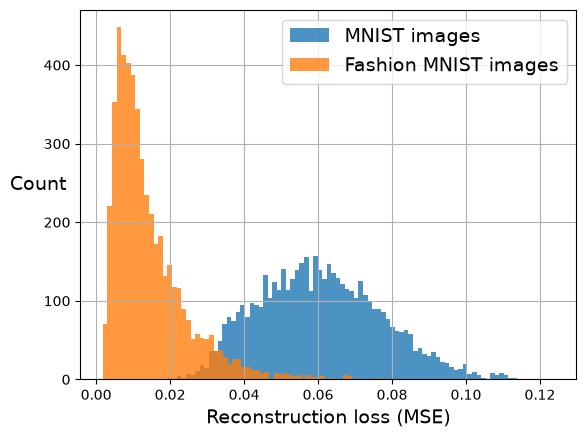

In [21]:
def compute_reconstruction_losses(X, device):
    X = X.to(device)
    with torch.no_grad():
        y_pred = stacked_ae(X)
        return (
            F.mse_loss(y_pred, X, reduction="none")
            .view(X.size(0), -1)
            .mean(dim=1)
            .cpu()
        )


recon_losses_mnist = compute_reconstruction_losses(mnist_images, device)
recon_losses_fashion_mnist = compute_reconstruction_losses(X_valid, device)

plt.hist(recon_losses_mnist, bins=85, alpha=0.8, label="MNIST images")
plt.hist(recon_losses_fashion_mnist, bins=85, alpha=0.8, label="Fashion MNIST images")
plt.xlabel("Reconstruction loss (MSE)")
plt.ylabel("Count", rotation=0)
plt.legend()
plt.grid()

plt.show()


> We will use a tactic to visualzie MNIST using an autoencoder and t-SNE


In [22]:
with torch.no_grad():
    X_valid_compressed = stacked_encoder(X_valid.to(device))

tsne = TSNE(init="pca", learning_rate="auto", random_state=42)
X_valid_2D = tsne.fit_transform(X_valid_compressed.cpu())

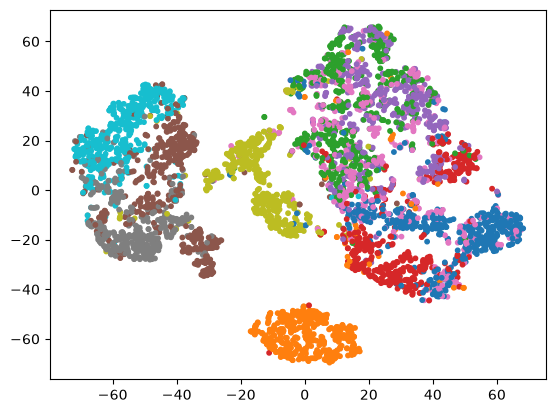

In [23]:
y_valid = torch.tensor([y for _, y in valid_data])

plt.scatter(X_valid_2D[:, 0], X_valid_2D[:, 1], c=y_valid, s=10, cmap="tab10")
plt.show()

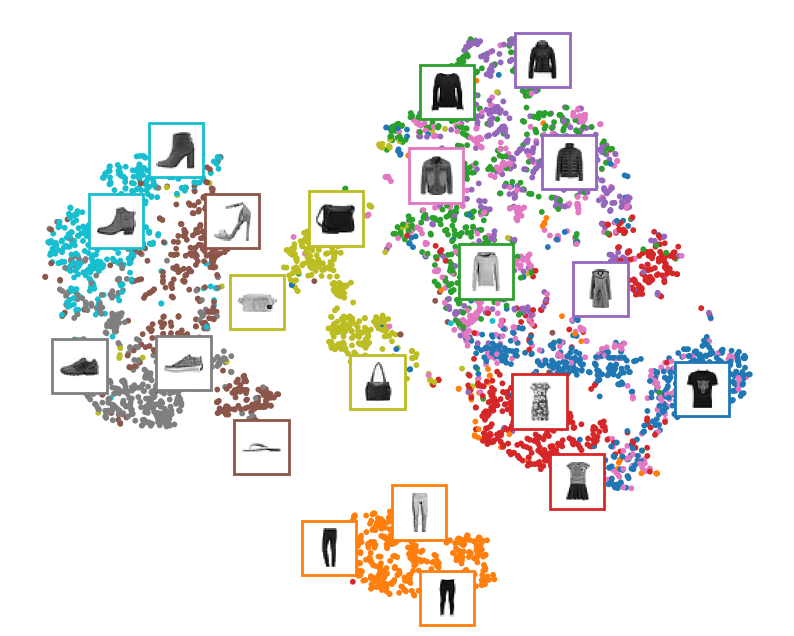

In [24]:
plt.figure(figsize=(10, 8))
cmap = plt.cm.tab10
Z = X_valid_2D
Z = (Z - Z.min()) / (Z.max() - Z.min())  # normalize to the 0-1 range
plt.scatter(Z[:, 0], Z[:, 1], c=y_valid, s=10, cmap=cmap)
image_positions = np.array([[1.0, 1.0]])
for index, position in enumerate(Z):
    dist = ((position - image_positions) ** 2).sum(axis=1)
    if dist.min() > 0.02:  # if far enough from other images
        image_positions = np.r_[image_positions, [position]]
        imagebox = mpl.offsetbox.AnnotationBbox(
            mpl.offsetbox.OffsetImage(X_valid[index].squeeze(dim=0), cmap="binary"),
            position,
            bboxprops={"edgecolor": cmap(y_valid[index]), "lw": 2},
        )
        plt.gca().add_artist(imagebox)

plt.axis("off")

plt.show()

In [25]:
class TiedAutoEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = nn.Linear(1 * 28 * 28, 128)
        self.enc2 = nn.Linear(128, 32)
        self.dec1_bias = nn.Parameter(torch.zeros(128))
        self.dec2_bias = nn.Parameter(torch.zeros(1 * 28 * 28))

    def encode(self, X):
        Z = X.view(-1, 1 * 28 * 28)
        Z = F.relu(self.enc1(Z))
        return F.relu(self.enc2(Z))

    def decode(self, X):
        Z = F.relu(F.linear(X, self.enc2.weight.t(), self.dec1_bias))
        Z = F.sigmoid(F.linear(Z, self.enc1.weight.t(), self.dec2_bias))
        return Z.view(-1, 1, 28, 28)

    def forward(self, X):
        return self.decode(self.encode(X))

In [26]:
tied_ae = TiedAutoEncoder().to(device)
optimizer = torch.optim.NAdam(tied_ae.parameters(), lr=0.01)
history = train(tied_ae, optimizer, mse, rmse, train_loader, valid_loader, n_epochs=20)

Epoch 1/20,                      train loss: 0.0229, train metric: 0.151, valid metric: 0.138
Epoch 2/20,                      train loss: 0.0173, train metric: 0.132, valid metric: 0.13
Epoch 3/20,                      train loss: 0.0166, train metric: 0.129, valid metric: 0.13
Epoch 4/20,                      train loss: 0.0162, train metric: 0.127, valid metric: 0.125
Epoch 5/20,                      train loss: 0.0140, train metric: 0.118, valid metric: 0.118
Epoch 6/20,                      train loss: 0.0136, train metric: 0.117, valid metric: 0.117
Epoch 7/20,                      train loss: 0.0134, train metric: 0.116, valid metric: 0.117
Epoch 8/20,                      train loss: 0.0126, train metric: 0.112, valid metric: 0.113
Epoch 9/20,                      train loss: 0.0124, train metric: 0.112, valid metric: 0.112
Epoch 10/20,                      train loss: 0.0123, train metric: 0.111, valid metric: 0.112
Epoch 11/20,                      train loss: 0.0119, train m

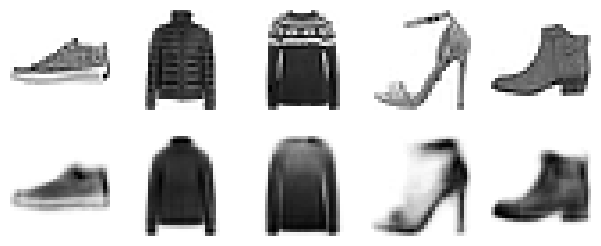

In [27]:
plot_reconstructions(tied_ae, X_valid)
plt.show()

### Convolutional AutoEncoder


In [28]:
conv_encoder = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding="same"),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),  # output: 16 × 14 × 14
    nn.Conv2d(16, 32, kernel_size=3, padding="same"),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),  # output: 32 × 7 × 7
    nn.Conv2d(32, 64, kernel_size=3, padding="same"),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),  # output: 64 × 3 × 3
    nn.Conv2d(64, 32, kernel_size=3, padding="same"),
    nn.ReLU(),
    nn.AdaptiveAvgPool2d((1, 1)),
    nn.Flatten(),
)  # output: 32

conv_decoder = nn.Sequential(
    nn.Linear(32, 16 * 3 * 3),
    nn.Unflatten(dim=1, unflattened_size=(16, 3, 3)),
    nn.ConvTranspose2d(16, 32, kernel_size=3, stride=2),
    nn.ReLU(),
    nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
    nn.ReLU(),
    nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
    nn.Sigmoid(),
)

conv_ae = nn.Sequential(conv_encoder, conv_decoder).to(device)


In [29]:
optimizer = torch.optim.NAdam(conv_ae.parameters(), lr=0.005)
history = train(conv_ae, optimizer, mse, rmse, train_loader, valid_loader, n_epochs=10)

Epoch 1/10,                      train loss: 0.0300, train metric: 0.173, valid metric: 0.139
Epoch 2/10,                      train loss: 0.0178, train metric: 0.133, valid metric: 0.128
Epoch 3/10,                      train loss: 0.0155, train metric: 0.124, valid metric: 0.124
Epoch 4/10,                      train loss: 0.0141, train metric: 0.119, valid metric: 0.116
Epoch 5/10,                      train loss: 0.0126, train metric: 0.112, valid metric: 0.112
Epoch 6/10,                      train loss: 0.0123, train metric: 0.111, valid metric: 0.11
Epoch 7/10,                      train loss: 0.0120, train metric: 0.109, valid metric: 0.109
Epoch 8/10,                      train loss: 0.0115, train metric: 0.107, valid metric: 0.108
Epoch 9/10,                      train loss: 0.0114, train metric: 0.107, valid metric: 0.107
Epoch 10/10,                      train loss: 0.0113, train metric: 0.106, valid metric: 0.107


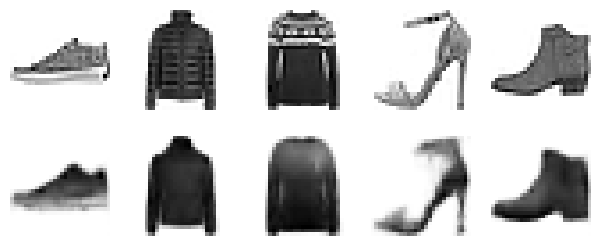

In [30]:
plot_reconstructions(conv_ae, X_valid)
plt.show()

### Denoising AutoEncoders


In [31]:
torch.manual_seed(42)

dropout_encoder = nn.Sequential(
    nn.Flatten(),
    nn.Dropout(0.5),
    nn.Linear(1 * 28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 128),
    nn.ReLU(),
)
dropout_decoder = nn.Sequential(
    nn.Linear(128, 128),
    nn.ReLU(),
    nn.Linear(128, 1 * 28 * 28),
    nn.Sigmoid(),
    nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)),
)
dropout_ae = nn.Sequential(dropout_encoder, dropout_decoder).to(device)

In [32]:
optimizer = torch.optim.NAdam(dropout_ae.parameters(), lr=0.01)
history = train(
    dropout_ae, optimizer, mse, rmse, train_loader, valid_loader, n_epochs=10
)

Epoch 1/10,                      train loss: 0.0278, train metric: 0.167, valid metric: 0.147
Epoch 2/10,                      train loss: 0.0229, train metric: 0.151, valid metric: 0.145
Epoch 3/10,                      train loss: 0.0225, train metric: 0.15, valid metric: 0.145
Epoch 4/10,                      train loss: 0.0222, train metric: 0.149, valid metric: 0.144
Epoch 5/10,                      train loss: 0.0202, train metric: 0.142, valid metric: 0.136
Epoch 6/10,                      train loss: 0.0198, train metric: 0.141, valid metric: 0.134
Epoch 7/10,                      train loss: 0.0196, train metric: 0.14, valid metric: 0.135
Epoch 8/10,                      train loss: 0.0186, train metric: 0.136, valid metric: 0.131
Epoch 9/10,                      train loss: 0.0184, train metric: 0.136, valid metric: 0.13
Epoch 10/10,                      train loss: 0.0183, train metric: 0.135, valid metric: 0.129


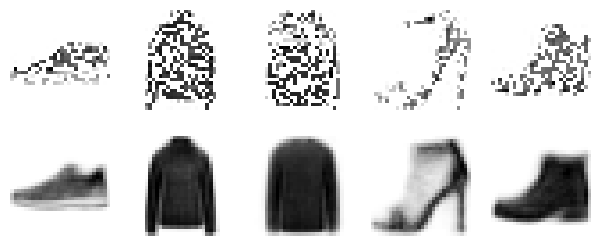

In [33]:
torch.manual_seed(42)
dropout = nn.Dropout(0.5)
plot_reconstructions(dropout_ae, dropout(X_valid))

plt.show()


In [34]:
## With gausian noise
class GaussianNoise(nn.Module):
    def __init__(self, std):
        super().__init__()
        self.std = std

    def forward(self, X):
        if self.training:  # only add noise during training
            noise = torch.randn_like(X) * self.std
            return X + noise
        return X


In [35]:
torch.manual_seed(42)
noise_encoder = nn.Sequential(
    nn.Flatten(),
    GaussianNoise(0.5),
    nn.Linear(1 * 28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 128),
    nn.ReLU(),
)
noise_decoder = nn.Sequential(
    nn.Linear(128, 128),
    nn.ReLU(),
    nn.Linear(128, 1 * 28 * 28),
    nn.Sigmoid(),
    nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)),
)
noise_ae = nn.Sequential(noise_encoder, noise_decoder).to(device)

In [36]:
optimizer = torch.optim.NAdam(noise_ae.parameters(), lr=0.01)
history = train(noise_ae, optimizer, mse, rmse, train_loader, valid_loader, n_epochs=10)

Epoch 1/10,                      train loss: 0.0291, train metric: 0.171, valid metric: 0.152
Epoch 2/10,                      train loss: 0.0239, train metric: 0.154, valid metric: 0.148
Epoch 3/10,                      train loss: 0.0235, train metric: 0.153, valid metric: 0.146
Epoch 4/10,                      train loss: 0.0233, train metric: 0.153, valid metric: 0.145
Epoch 5/10,                      train loss: 0.0214, train metric: 0.146, valid metric: 0.139
Epoch 6/10,                      train loss: 0.0211, train metric: 0.145, valid metric: 0.138
Epoch 7/10,                      train loss: 0.0208, train metric: 0.144, valid metric: 0.137
Epoch 8/10,                      train loss: 0.0199, train metric: 0.141, valid metric: 0.133
Epoch 9/10,                      train loss: 0.0196, train metric: 0.14, valid metric: 0.132
Epoch 10/10,                      train loss: 0.0195, train metric: 0.14, valid metric: 0.132


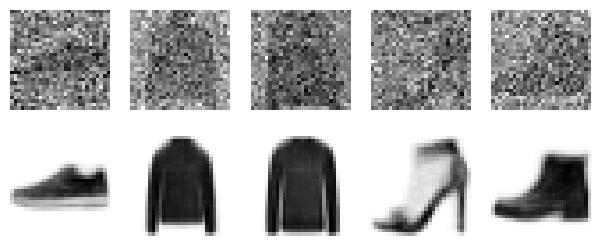

In [37]:
torch.manual_seed(42)
noise = GaussianNoise(0.5)
plot_reconstructions(noise_ae, noise(X_valid))
plt.show()

### Sparse AutoEncoder


In [19]:
AEOutput = namedtuple("AEOutput", ["output", "codings"])


class SparseAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1 * 28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.Sigmoid(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 1 * 28 * 28),
            nn.Sigmoid(),
            nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)),
        )

    def forward(self, X):
        codings = self.encoder(X)
        output = self.decoder(codings)
        return AEOutput(output, codings)

In [20]:
def mse_plus_sparsity_loss(
    y_pred, y_target, target_sparsity=0.1, kl_weight=1e-3, eps=1e-8
):
    p = torch.tensor(target_sparsity, device=y_pred.codings.device)
    q = torch.clamp(y_pred.codings.mean(dim=0), eps, 1 - eps)  # actual sparsity
    kl_div = p * torch.log(p / q) + (1 - p) * torch.log((1 - p) / (1 - q))
    return mse(y_pred.output, y_target) + kl_weight * kl_div.sum()

In [21]:
torch.manual_seed(42)
sparse_ae = SparseAutoencoder().to(device)
mse = nn.MSELoss()
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
optimizer = torch.optim.NAdam(sparse_ae.parameters(), lr=0.002)
history = train(
    sparse_ae,
    optimizer,
    mse_plus_sparsity_loss,
    rmse,
    train_loader,
    valid_loader,
    n_epochs=10,
)

Epoch 1/10,                      train loss: 0.0287, train metric: 0.165, valid metric: 0.134
Epoch 2/10,                      train loss: 0.0163, train metric: 0.125, valid metric: 0.121
Epoch 3/10,                      train loss: 0.0135, train metric: 0.113, valid metric: 0.112
Epoch 4/10,                      train loss: 0.0118, train metric: 0.106, valid metric: 0.105
Epoch 5/10,                      train loss: 0.0103, train metric: 0.0995, valid metric: 0.0988
Epoch 6/10,                      train loss: 0.0098, train metric: 0.097, valid metric: 0.097
Epoch 7/10,                      train loss: 0.0093, train metric: 0.0949, valid metric: 0.0958
Epoch 8/10,                      train loss: 0.0088, train metric: 0.0923, valid metric: 0.0928
Epoch 9/10,                      train loss: 0.0086, train metric: 0.0913, valid metric: 0.0921
Epoch 10/10,                      train loss: 0.0084, train metric: 0.0904, valid metric: 0.0911


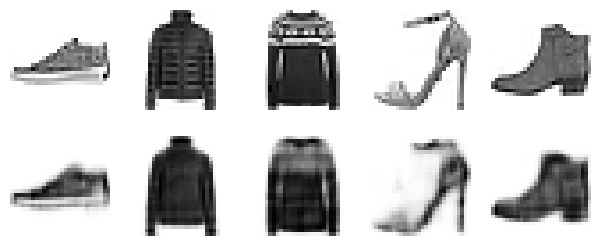

In [48]:
plot_reconstructions(sparse_ae, X_valid)
plt.show()

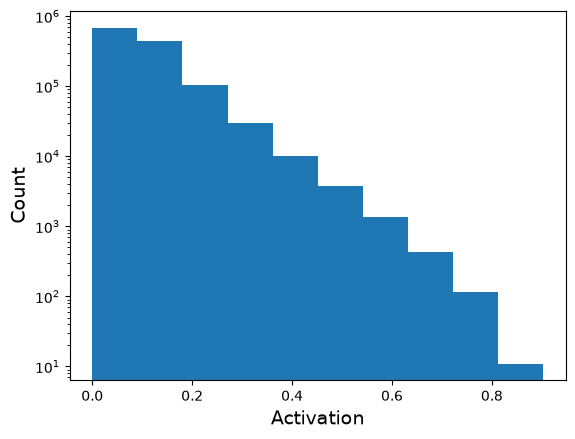

In [49]:
with torch.no_grad():
    y_pred = sparse_ae(X_valid.to(device))

encs = y_pred.codings.flatten().detach().cpu()
plt.hist(encs, log=True)
plt.xlabel("Activation")
plt.ylabel("Count")
plt.show()

In [24]:
def plot_multiple_images(images, n_cols=None):
    n_cols = n_cols or len(images)
    n_rows = (len(images) - 1) // n_cols + 1
    plt.figure(figsize=(n_cols, n_rows))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plot_image(image)


# dim = 6
# codings = y_pred.codings[:, dim].cpu()
# threshold = np.percentile(codings, 90)
# selected_images = X_valid[codings > threshold]
# plot_multiple_images(selected_images[:35], 7)
# plt.show()

In [ ]:
VAEOutput = namedtuple("VAEOutput", ["output", "codings_mean", "codings_logvar"])


class VAE(nn.Module):
    def __init__(self, codings_dim=32):
        super(VAE, self).__init__()
        self.codings_dim = codings_dim
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1 * 28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 2 * codings_dim),
        )  # output both the mean and logvar
        self.decoder = nn.Sequential(
            nn.Linear(codings_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1 * 28 * 28),
            nn.Sigmoid(),
            nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)),
        )

    def encode(self, X):
        return self.encoder(X).chunk(2, dim=-1)  # returns (mean, logvar)

    def sample_codings(self, codings_mean, codings_logvar):
        codings_std = torch.exp(0.5 * codings_logvar)
        noise = torch.randn_like(codings_std)
        return codings_mean + noise * codings_std

    def decode(self, Z):
        return self.decoder(Z)

    def forward(self, X):
        codings_mean, codings_logvar = self.encode(X)
        codings = self.sample_codings(codings_mean, codings_logvar)
        output = self.decode(codings)
        return VAEOutput(output, codings_mean, codings_logvar)

In [52]:
def vae_loss(y_pred, y_target, kl_weight=1.0):
    output, mean, logvar = y_pred
    kl_div = -0.5 * torch.sum(1 + logvar - logvar.exp() - mean.square(), dim=-1)
    return F.mse_loss(output, y_target) + kl_weight * kl_div.mean() / 784

In [53]:
torch.manual_seed(42)
vae = VAE().to(device)
optimizer = torch.optim.NAdam(vae.parameters(), lr=1e-3)
history = train(vae, optimizer, vae_loss, rmse, train_loader, valid_loader, n_epochs=20)

Epoch 1/20,                      train loss: 0.0486, train metric: 0.198, valid metric: 0.173
Epoch 2/20,                      train loss: 0.0369, train metric: 0.165, valid metric: 0.162
Epoch 3/20,                      train loss: 0.0350, train metric: 0.158, valid metric: 0.157
Epoch 4/20,                      train loss: 0.0340, train metric: 0.155, valid metric: 0.155
Epoch 5/20,                      train loss: 0.0333, train metric: 0.152, valid metric: 0.152
Epoch 6/20,                      train loss: 0.0330, train metric: 0.151, valid metric: 0.15
Epoch 7/20,                      train loss: 0.0328, train metric: 0.15, valid metric: 0.151
Epoch 8/20,                      train loss: 0.0325, train metric: 0.149, valid metric: 0.15
Epoch 9/20,                      train loss: 0.0324, train metric: 0.149, valid metric: 0.148
Epoch 10/20,                      train loss: 0.0323, train metric: 0.149, valid metric: 0.149
Epoch 11/20,                      train loss: 0.0322, train me

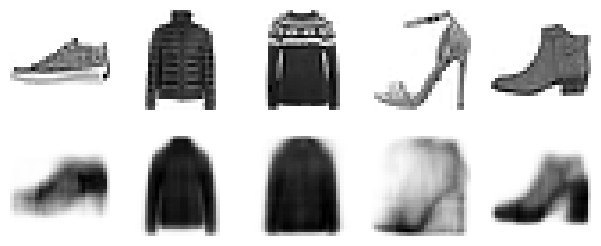

In [54]:
plot_reconstructions(vae, X_valid)
plt.show()

In [55]:
torch.manual_seed(42)  # extra code – ensures reproducibility

vae.eval()
codings = torch.randn(3 * 7, vae.codings_dim, device=device)
with torch.no_grad():
    images = vae.decode(codings)


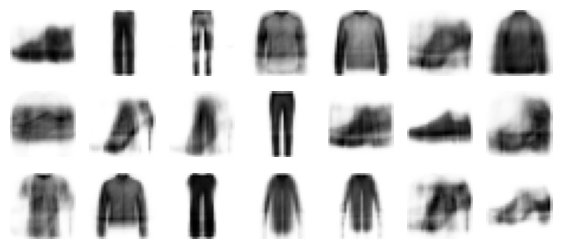

In [56]:
plot_multiple_images(images, 7)

plt.show()

In [57]:
torch.manual_seed(111)  # extra code – ensure reproducibility

codings = torch.randn(2, vae.codings_dim)  # start and end codings
n_images = 7
weights = torch.linspace(0, 1, n_images).view(n_images, 1)
codings = torch.lerp(codings[0], codings[1], weights)  # linear interpolation
with torch.no_grad():
    images = vae.decode(codings.to(device))

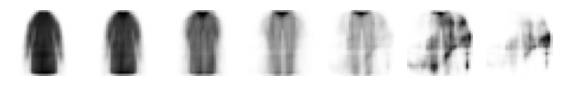

In [58]:
plot_multiple_images(images)

plt.show()

In [ ]:
# Bug on mps so we have to use a self implemented softmax-gumbel function
def gumbel_softmax(logits, tau=1, hard=False, dim=-1):
    if device != "mps":
        return F.gumbel_softmax(logits, tau, hard, dim)
    gumbels = (
        -torch.empty_like(logits, memory_format=torch.legacy_contiguous_format)
        .exponential_()
        .log()
    )  # ~Gumbel(0,1)
    gumbels = torch.clamp(gumbels, -30, 30)  # <<<<<<<<<<<<<<<<<<<<< ADDED
    gumbels = (logits + gumbels) / tau  # ~Gumbel(logits,tau)
    y_soft = gumbels.softmax(dim)

    if hard:
        # Straight through.
        index = y_soft.max(dim, keepdim=True)[1]
        y_hard = torch.zeros_like(
            logits, memory_format=torch.legacy_contiguous_format
        ).scatter_(dim, index, 1.0)
        ret = y_hard - y_soft.detach() + y_soft
    else:
        # Reparametrization trick.
        ret = y_soft
    return ret


In [ ]:
DiscreteVAEOutput = namedtuple(
    "DiscreteVAEOutput", ["output", "logits", "codings_prob"]
)


class DiscreteVAE(nn.Module):
    def __init__(self, coding_length=32, n_codes=16, temperature=1.0):
        super().__init__()
        self.coding_length = coding_length
        self.n_codes = n_codes
        self.temperature = temperature
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1 * 28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, coding_length * n_codes),
            nn.Unflatten(dim=1, unflattened_size=(coding_length, n_codes)),
        )
        self.decoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(coding_length * n_codes, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 1 * 28 * 28),
            nn.Sigmoid(),
            nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)),
        )

    def forward(self, X):
        logits = self.encoder(X)
        codings_prob = gumbel_softmax(logits, tau=self.temperature, hard=True)
        output = self.decoder(codings_prob)
        return DiscreteVAEOutput(output, logits, codings_prob)


In [16]:
def d_vae_loss(y_pred, y_target, kl_weight=1.0):
    output, logits, _ = y_pred
    codings_prob = F.softmax(logits, -1)
    k = logits.new_tensor(logits.size(-1))  # same device and dtype as logits
    kl_div = (codings_prob * (codings_prob.log() + k.log())).sum(dim=(1, 2))
    return F.mse_loss(output, y_target) + kl_weight * kl_div.mean() / 784

In [18]:
n_epochs = 20


def annealing(model, epoch):
    model.temperature = 1 - 0.9 * epoch / n_epochs


torch.manual_seed(42)
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
d_vae = DiscreteVAE().to(device)
optimizer = torch.optim.NAdam(d_vae.parameters(), lr=0.001)
history = train(
    d_vae,
    optimizer,
    d_vae_loss,
    rmse,
    train_loader,
    valid_loader,
    n_epochs=n_epochs,
    epoch_callback=annealing,
)

Epoch 1/20,                      train loss: 0.0582, train metric: 0.229, valid metric: 0.207
Epoch 2/20,                      train loss: 0.0480, train metric: 0.2, valid metric: 0.194
Epoch 3/20,                      train loss: 0.0441, train metric: 0.189, valid metric: 0.187
Epoch 4/20,                      train loss: 0.0423, train metric: 0.185, valid metric: 0.184
Epoch 5/20,                      train loss: 0.0407, train metric: 0.18, valid metric: 0.18
Epoch 6/20,                      train loss: 0.0400, train metric: 0.179, valid metric: 0.18
Epoch 7/20,                      train loss: 0.0393, train metric: 0.177, valid metric: 0.178
Epoch 8/20,                      train loss: 0.0385, train metric: 0.175, valid metric: 0.176
Epoch 9/20,                      train loss: 0.0381, train metric: 0.174, valid metric: 0.175
Epoch 10/20,                      train loss: 0.0378, train metric: 0.173, valid metric: 0.174
Epoch 11/20,                      train loss: 0.0373, train metr

In [19]:
torch.manual_seed(42)  # extra code – ensures reproducibility
n_images = 3 * 7
codings = torch.randint(
    0,
    d_vae.n_codes,  # from 0 to k – 1
    (n_images, d_vae.coding_length),
    device=device,
)
codings_prob = F.one_hot(codings, num_classes=d_vae.n_codes).float()
with torch.no_grad():
    images = d_vae.decoder(codings_prob)


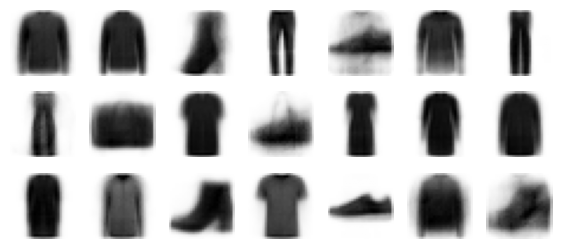

In [25]:
plot_multiple_images(images, 7)
plt.show()

### Generative Adversial Networks


In [ ]:
torch.manual_seed(42)  # extra code – ensures reproducibility

codings_dim = 32
generator = nn.Sequential(
    nn.Linear(codings_dim, 128),
    nn.ReLU(),
    nn.Linear(128, 256),
    nn.ReLU(),
    nn.Linear(256, 1 * 28 * 28),
    nn.Sigmoid(),
    nn.Unflatten(dim=1, unflattened_size=(1, 28, 28)),
).to(device)
discriminator = nn.Sequential(
    nn.Flatten(),
    nn.Linear(1 * 28 * 28, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 1),
    nn.Sigmoid(),
).to(device)

In [ ]:
def train_gan(
    generator,
    discriminator,
    train_loader,
    codings_dim,
    n_epochs=20,
    g_lr=1e-3,
    d_lr=5e-4,
):
    criterion = nn.BCELoss()
    generator_opt = torch.optim.NAdam(generator.parameters(), lr=g_lr)
    discriminator_opt = torch.optim.NAdam(discriminator.parameters(), lr=d_lr)
    for epoch in range(n_epochs):
        print(f"Epoch {epoch + 1}/{n_epochs}", end="")
        for real_images, _ in train_loader:
            real_images = real_images.to(device)
            pred_real = discriminator(real_images)
            batch_size = real_images.size(0)
            ones = torch.ones(batch_size, 1, device=device)
            real_loss = criterion(pred_real, ones)
            codings = torch.randn(batch_size, codings_dim, device=device)
            fake_images = generator(codings).detach()
            pred_fake = discriminator(fake_images)
            zeros = torch.zeros(batch_size, 1, device=device)
            fake_loss = criterion(pred_fake, zeros)
            discriminator_loss = real_loss + fake_loss
            discriminator_opt.zero_grad()
            discriminator_loss.backward()
            discriminator_opt.step()

            codings = torch.randn(batch_size, codings_dim, device=device)
            fake_images = generator(codings)
            for p in discriminator.parameters():
                p.requires_grad = False
            pred_fake = discriminator(fake_images)
            generator_loss = criterion(pred_fake, ones)
            generator_opt.zero_grad()
            generator_loss.backward()
            generator_opt.step()
            for p in discriminator.parameters():
                p.requires_grad = True
        print(f" | discriminator loss: {discriminator_loss.item():.4f}", end="")
        print(f" | generator loss: {generator_loss.item():.4f}")
        if epoch % 10 == 0 or epoch == n_epochs - 1:
            plot_multiple_images(fake_images.detach(), 8)
            plt.show()


Epoch 1/20 | discriminator loss: 0.5807 | generator loss: 1.9967


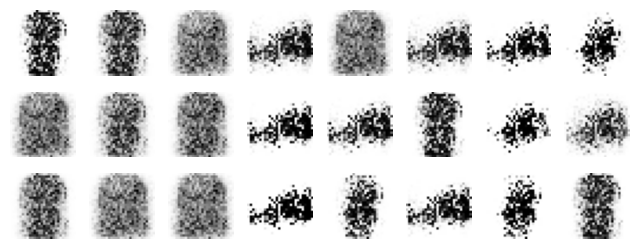

Epoch 2/20 | discriminator loss: 0.4997 | generator loss: 2.1314
Epoch 3/20 | discriminator loss: 0.7668 | generator loss: 1.5368
Epoch 4/20 | discriminator loss: 0.8629 | generator loss: 1.8695
Epoch 5/20 | discriminator loss: 0.8741 | generator loss: 1.9926
Epoch 6/20 | discriminator loss: 0.4148 | generator loss: 2.0218
Epoch 7/20 | discriminator loss: 0.8391 | generator loss: 2.2237
Epoch 8/20 | discriminator loss: 0.8269 | generator loss: 2.3847
Epoch 9/20 | discriminator loss: 0.9074 | generator loss: 2.9840
Epoch 10/20 | discriminator loss: 0.8639 | generator loss: 1.3227
Epoch 11/20 | discriminator loss: 0.8198 | generator loss: 2.2677


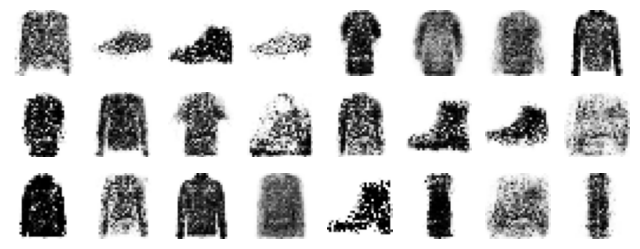

Epoch 12/20 | discriminator loss: 0.7977 | generator loss: 1.6716
Epoch 13/20 | discriminator loss: 0.5929 | generator loss: 2.2851
Epoch 14/20 | discriminator loss: 1.1927 | generator loss: 1.4649
Epoch 15/20 | discriminator loss: 1.2466 | generator loss: 1.5758
Epoch 16/20 | discriminator loss: 0.9546 | generator loss: 1.3948
Epoch 17/20 | discriminator loss: 0.8199 | generator loss: 3.0707
Epoch 18/20 | discriminator loss: 1.3550 | generator loss: 1.2454
Epoch 19/20 | discriminator loss: 1.0709 | generator loss: 0.9710
Epoch 20/20 | discriminator loss: 0.6500 | generator loss: 2.0381


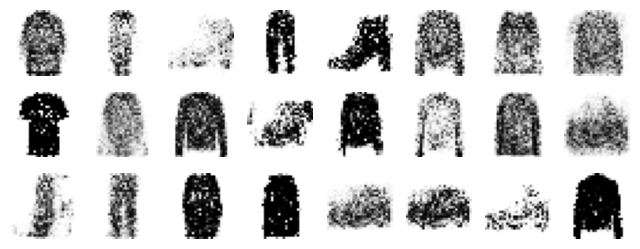

In [28]:
torch.manual_seed(41)  # trying another seed often fixes the issue 😅
train_gan(generator, discriminator, train_loader, codings_dim)

In [29]:
torch.manual_seed(42)  # extra code – ensures reproducibility
n_images = 3 * 7
generator.eval()
codings = torch.randn(n_images, codings_dim, device=device)
with torch.no_grad():
    generated_images = generator(codings)

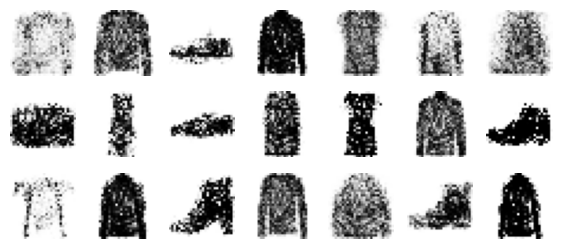

In [30]:
plot_multiple_images(generated_images, 7)
plt.show()

In [31]:
torch.manual_seed(1)  # extra code – ensures reproducibility

dc_codings_dim = 100

dc_generator = nn.Sequential(
    nn.Linear(dc_codings_dim, 128 * 7 * 7),
    nn.Unflatten(dim=1, unflattened_size=(128, 7, 7)),
    nn.BatchNorm2d(128),
    nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
    nn.ReLU(),
    nn.BatchNorm2d(64),
    nn.ConvTranspose2d(64, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
    nn.Sigmoid(),
).to(device)
dc_discriminator = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=5, stride=2, padding=2),
    nn.ReLU(),  # 32 x 14 x 14
    nn.Dropout(0.4),
    nn.Conv2d(32, 64, kernel_size=5, stride=2, padding=2),
    nn.ReLU(),  # 64 x 7 x 7
    nn.Dropout(0.4),
    nn.Flatten(),
    nn.Linear(64 * 7 * 7, 1),
    nn.Sigmoid(),
).to(device)


Epoch 1/20 | discriminator loss: 1.4319 | generator loss: 0.8337


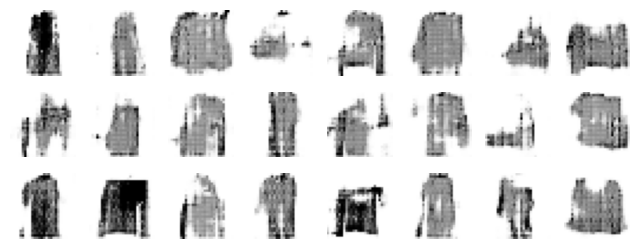

Epoch 2/20 | discriminator loss: 1.3667 | generator loss: 0.9536
Epoch 3/20 | discriminator loss: 0.9138 | generator loss: 1.0930
Epoch 4/20 | discriminator loss: 0.9763 | generator loss: 1.2375
Epoch 5/20 | discriminator loss: 1.0960 | generator loss: 1.1178
Epoch 6/20 | discriminator loss: 0.7971 | generator loss: 1.3674
Epoch 7/20 | discriminator loss: 0.9820 | generator loss: 1.1363
Epoch 8/20 | discriminator loss: 0.7207 | generator loss: 1.3726
Epoch 9/20 | discriminator loss: 0.8176 | generator loss: 1.6803
Epoch 10/20 | discriminator loss: 0.9064 | generator loss: 1.6616
Epoch 11/20 | discriminator loss: 0.4859 | generator loss: 1.4865


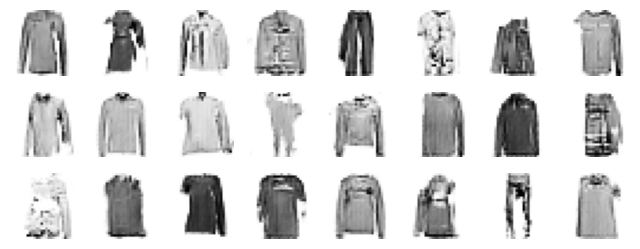

Epoch 12/20 | discriminator loss: 0.8081 | generator loss: 1.2479
Epoch 13/20 | discriminator loss: 1.0746 | generator loss: 1.6376
Epoch 14/20 | discriminator loss: 0.7781 | generator loss: 1.7776
Epoch 15/20 | discriminator loss: 0.7555 | generator loss: 1.8571
Epoch 16/20 | discriminator loss: 0.6618 | generator loss: 1.7888
Epoch 17/20 | discriminator loss: 0.5687 | generator loss: 1.6681
Epoch 18/20 | discriminator loss: 0.4519 | generator loss: 1.9039
Epoch 19/20 | discriminator loss: 0.4501 | generator loss: 1.5781
Epoch 20/20 | discriminator loss: 0.6413 | generator loss: 1.6824


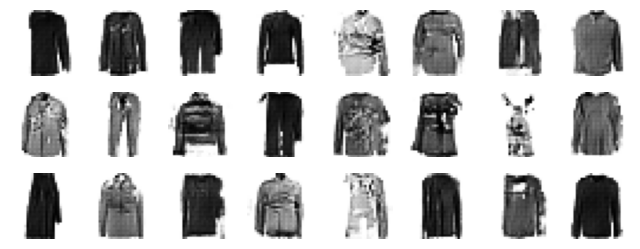

In [32]:
torch.manual_seed(42)
train_gan(dc_generator, dc_discriminator, train_loader, dc_codings_dim)

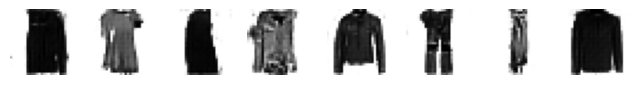

In [33]:
torch.manual_seed(42)
with torch.no_grad():
    codings = torch.randn(8, dc_codings_dim, device=device)
    generated_images = dc_generator(codings)
plot_multiple_images(generated_images, 8)

In [ ]:
def variance_schedule(T, s=0.008, max_beta=0.999):
    t = torch.linspace(0, T, T + 1)
    f = torch.cos((t / T + s) / (1 + s) * torch.pi / 2) ** 2
    alpha_bars = f / f[0]
    betas = (1 - (f[1:] / f[:-1])).clamp(max=max_beta)
    betas = torch.cat([torch.zeros(1), betas])  # for easier indexing
    alphas = 1 - betas
    return alphas, betas, alpha_bars


torch.manual_seed(42)  # extra code – for reproducibility
T = 4000
alphas, betas, alpha_bars = variance_schedule(T)

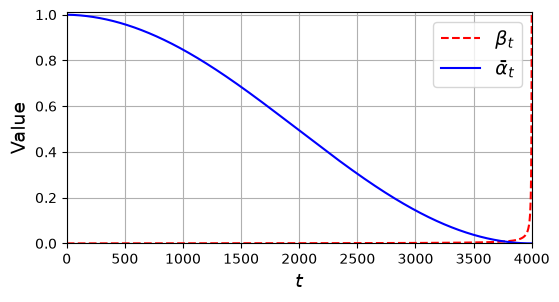

In [35]:
# extra code – this cell generates Figure 18–21
plt.figure(figsize=(6, 3))
plt.plot(betas, "r--", label=r"$\beta_t$")
plt.plot(alpha_bars, "b", label=r"$\bar{\alpha}_t$")
plt.axis([0, T, 0, 1.01])
plt.grid(True)
plt.xlabel("$t$")
plt.ylabel(r"Value")
plt.legend()

plt.show()

In [36]:
def forward_diffusion(x0, t):
    eps = torch.randn_like(x0)  # this unscaled noise will be the target
    xt = alpha_bars[t].sqrt() * x0 + (1 - alpha_bars[t]).sqrt() * eps
    return xt, eps

In [37]:
class DiffusionSample(namedtuple("DiffusionSampleBase", ["xt", "t"])):
    def to(self, device):
        return DiffusionSample(self.xt.to(device), self.t.to(device))

In [ ]:
class DiffusionDataset:
    def __init__(self, dataset):
        self.dataset = dataset

    def __getitem__(self, i):
        x0, _ = self.dataset[i]
        x0 = (x0 * 2) - 1  # scale from –1 to +1
        t = torch.randint(1, T + 1, size=[1])
        xt, eps = forward_diffusion(x0, t)
        return DiffusionSample(xt, t), eps

    def __len__(self):
        return len(self.dataset)


train_set = DiffusionDataset(train_data)  # wrap Fashion MNIST
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)

In [39]:
valid_set = DiffusionDataset(valid_data)
valid_loader = DataLoader(valid_set, batch_size=32)


Original images


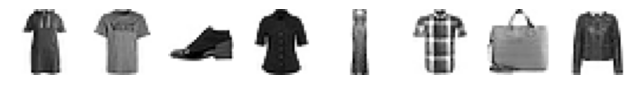

Time steps: [2027, 1463, 3720, 9, 611, 2202, 2118, 388]
Noisy images


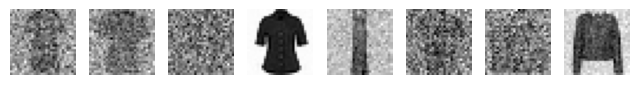

Noise to predict


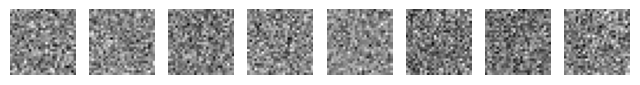

In [ ]:
# extra code – just a quick sanity check


def original_image(sample, noise):
    alpha_bars_t = torch.gather(alpha_bars, dim=0, index=sample.t.squeeze(1))
    alpha_bars_t = alpha_bars_t.view(-1, 1, 1, 1)
    x0 = (sample.xt - (1 - alpha_bars_t).sqrt() * noise) / alpha_bars_t.sqrt()
    return torch.clamp((x0 + 1) / 2, 0, 1)


torch.manual_seed(42)
sample, eps = next(iter(train_loader))  # get the first batch
x0 = original_image(sample, eps).to(device)

print("Original images")
plot_multiple_images(x0[:8])
plt.show()
print("Time steps:", sample.t[:8].view(-1).tolist())
print("Noisy images")
plot_multiple_images(sample.xt[:8])
plt.show()
print("Noise to predict")
plot_multiple_images(eps[:8])
plt.show()

In [ ]:
embed_dim = 64


class TimeEncoding(nn.Module):
    def __init__(self, T, embed_dim):
        super().__init__()
        assert embed_dim % 2 == 0, "embed_dim must be even"
        p = torch.arange(T + 1).unsqueeze(1)
        angle = p / 10_000 ** (torch.arange(0, embed_dim, 2) / embed_dim)
        te = torch.empty(T + 1, embed_dim)
        te[:, 0::2] = torch.sin(angle)
        te[:, 1::2] = torch.cos(angle)
        self.register_buffer("time_encodings", te)

    def forward(self, t):
        return self.time_encodings[t]

In [ ]:
class SeparableConv2d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, padding):
        super().__init__()
        self.depthwise = nn.Conv2d(
            in_channels, in_channels, kernel_size, padding=padding, groups=in_channels
        )
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1)

    def forward(self, X):
        return self.pointwise(self.depthwise(X))


class DiffusionModel(nn.Module):
    def __init__(self, T=T, embed_dim=64):
        super().__init__()
        self.time_encoding = TimeEncoding(T, embed_dim)

        # Init
        dim = 16
        self.pad = nn.ConstantPad2d((3, 3, 3, 3), 0)
        self.init_conv = nn.Conv2d(1, dim, kernel_size=3)
        self.init_bn = nn.BatchNorm2d(dim)
        self.time_adapter_init = nn.Linear(embed_dim, dim)

        # Down path
        self.down_blocks = nn.ModuleList()
        self.skip_convs = nn.ModuleList()
        self.time_adapters_down = nn.ModuleList()
        in_dim = dim
        for dim in (32, 64, 128):
            block = nn.Sequential(
                nn.ReLU(),
                SeparableConv2d(in_dim, dim, kernel_size=3, padding=1),
                nn.BatchNorm2d(dim),
                nn.ReLU(),
                SeparableConv2d(dim, dim, kernel_size=3, padding=1),
                nn.BatchNorm2d(dim),
            )
            skip_conv = nn.Conv2d(in_dim, dim, kernel_size=1, stride=2)
            self.down_blocks.append(block)
            self.skip_convs.append(skip_conv)
            self.time_adapters_down.append(nn.Linear(embed_dim, dim))
            in_dim = dim

        # Up path
        self.up_blocks = nn.ModuleList()
        self.skip_up_convs = nn.ModuleList()
        self.time_adapters_up = nn.ModuleList()
        for dim in (64, 32, 16):
            block = nn.Sequential(
                nn.ReLU(),
                nn.ConvTranspose2d(in_dim, dim, 3, padding=1),
                nn.BatchNorm2d(dim),
                nn.ReLU(),
                nn.ConvTranspose2d(dim, dim, 3, padding=1),
                nn.BatchNorm2d(dim),
            )
            skip_conv = nn.Conv2d(in_dim, dim, kernel_size=1)
            self.up_blocks.append(block)
            self.skip_up_convs.append(skip_conv)
            self.time_adapters_up.append(nn.Linear(embed_dim, dim))
            in_dim = dim * 3  # because of concatenation with cross skip

        self.final_conv = nn.Conv2d(in_dim, 1, 3, padding=1)

    def forward(self, sample):
        if not isinstance(sample, DiffusionSample):
            print(repr(sample))
        time_enc = self.time_encoding(sample.t.squeeze(1))  # [batch, embed_dim]
        z = self.pad(sample.xt)
        z = F.relu(self.init_bn(self.init_conv(z)))
        z = z + self.time_adapter_init(time_enc)[:, :, None, None]
        skip = z
        cross_skips = []

        # Downsampling path
        for block, skip_conv, time_adapter in zip(
            self.down_blocks, self.skip_convs, self.time_adapters_down
        ):
            z = block(z)
            cross_skips.append(z)
            z = F.max_pool2d(z, 3, stride=2, padding=1)
            skip_link = skip_conv(skip)
            z = z + skip_link
            z = z + time_adapter(time_enc)[:, :, None, None]
            skip = z

        # Upsampling path
        for block, skip_up_conv, time_adapter in zip(
            self.up_blocks, self.skip_up_convs, self.time_adapters_up
        ):
            z = block(z)
            z = F.interpolate(z, scale_factor=2, mode="nearest")
            skip_link = F.interpolate(skip, scale_factor=2, mode="nearest")
            skip_link = skip_up_conv(skip_link)
            z = z + skip_link
            z = z + time_adapter(time_enc)[:, :, None, None]
            cross_skip = cross_skips.pop()
            z = torch.cat([z, cross_skip], dim=1)
            skip = z

        out = self.final_conv(z)
        out = out[:, :, 2:-2, 2:-2]  # cropping
        return out.contiguous()


In [43]:
torch.manual_seed(42)
diffusion_model = DiffusionModel().to(device)
huber = nn.HuberLoss()
optimizer = torch.optim.NAdam(diffusion_model.parameters(), lr=3e-3)
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)
history = train(
    diffusion_model, optimizer, huber, rmse, train_loader, valid_loader, n_epochs=20
)

Epoch 1/20,                      train loss: 0.0657, train metric: 0.376, valid metric: 0.331
Epoch 2/20,                      train loss: 0.0476, train metric: 0.318, valid metric: 0.315
Epoch 3/20,                      train loss: 0.1280, train metric: 1.89, valid metric: 0.307
Epoch 4/20,                      train loss: 0.0440, train metric: 0.306, valid metric: 0.3
Epoch 5/20,                      train loss: 0.0417, train metric: 0.298, valid metric: 0.295
Epoch 6/20,                      train loss: 0.0413, train metric: 0.297, valid metric: 0.296
Epoch 7/20,                      train loss: 0.0411, train metric: 0.296, valid metric: 0.292
Epoch 8/20,                      train loss: 0.0404, train metric: 0.294, valid metric: 0.294
Epoch 9/20,                      train loss: 0.0401, train metric: 0.292, valid metric: 0.292
Epoch 10/20,                      train loss: 0.0402, train metric: 0.293, valid metric: 0.289
Epoch 11/20,                      train loss: 0.0394, train me

In [44]:
def generate_ddpm(model, batch_size=32):
    model.eval()
    with torch.no_grad():
        xt = torch.randn([batch_size, 1, 28, 28], device=device)
        for t in range(T, 0, -1):
            print(f"\rt = {t}", end=" ")  # extra code — show progress
            alpha_t = alphas[t]
            beta_t = betas[t]
            alpha_bar_t = alpha_bars[t]
            noise = (
                torch.randn(xt.shape, device=device)
                if t > 1
                else torch.zeros(xt.shape, device=device)
            )
            t_batch = torch.full((batch_size, 1), t, device=device)
            sample = DiffusionSample(xt, t_batch)
            eps_pred = model(sample)
            xt = (
                1 / alpha_t.sqrt() * (xt - beta_t / (1 - alpha_bar_t).sqrt() * eps_pred)
                + (1 - alpha_t).sqrt() * noise
            )
        return torch.clamp((xt + 1) / 2, 0, 1)


torch.manual_seed(42)  # extra code – ensures reproducibility
X_gen = generate_ddpm(diffusion_model)  # generated images

t = 1    

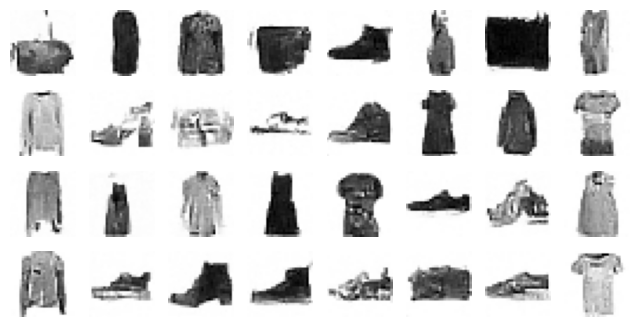

In [45]:
plot_multiple_images(X_gen, 8)
plt.show()

In [46]:
def generate_ddim(model, batch_size=32, num_steps=50, eta=0.85):
    model.eval()
    with torch.no_grad():
        xt = torch.randn([batch_size, 1, 28, 28], device=device)
        times = torch.linspace(T - 1, 0, steps=num_steps + 1).long().tolist()
        for t, t_prev in zip(times[:-1], times[1:]):
            print(f"\rt = {t}", end=" ")
            t_batch = torch.full((batch_size, 1), t, device=device)
            sample = DiffusionSample(xt, t_batch)
            eps_pred = model(sample)
            x0 = (xt - (1 - alpha_bars[t]).sqrt() * eps_pred) / (alpha_bars[t].sqrt())
            abar_t_prev = alpha_bars[t_prev]
            variance = eta * (1 - abar_t_prev) / (1 - alpha_bars[t]) * betas[t]
            sigma_t = variance.sqrt()
            pred_dir = (1 - abar_t_prev - sigma_t**2).sqrt() * eps_pred
            noise = torch.randn_like(xt)
            xt = abar_t_prev.sqrt() * x0 + pred_dir + sigma_t * noise

        return torch.clamp((xt + 1) / 2, 0, 1)  # from [–1, 1] range to [0, 1]


torch.manual_seed(42)  # extra code – ensures reproducibility
X_gen_ddim = generate_ddim(diffusion_model, num_steps=500)

t = 7    

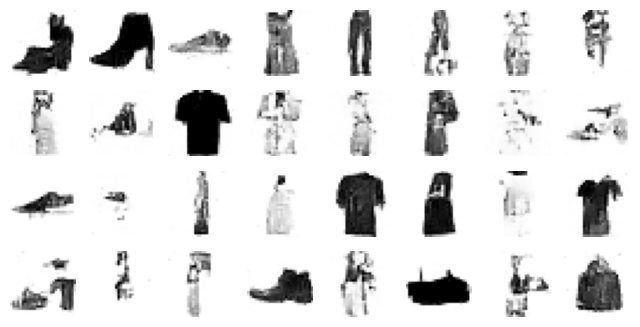

In [47]:
plot_multiple_images(X_gen_ddim, 8)
plt.show()

In [5]:
from diffusers import AutoPipelineForText2Image

pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo", variant="fp16", dtype=torch.float16
)
pipe.to(device)
prompt = "A closeup photo of an orangutan reading a book"

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/1 [00:00<?, ?it/s]

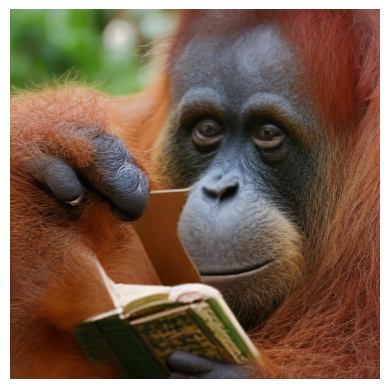

In [6]:
torch.manual_seed(42)
image = pipe(prompt=prompt, num_inference_steps=1, guidance_scale=0.0).images[0]
image.save("my_orangutan_reading.png")
plt.imshow(image)
plt.axis("off")
plt.show()